# SSPMS — Modelling notebook (US6 · US7 · US8)

**Smart Student Performance Monitoring System** — predicting which students are at risk
of failing or withdrawing, by **week 6** of the course.

| Story | Title | Owner | What this notebook does |
|---|---|---|---|
| **US6** | Baseline At-Risk Prediction Model | Zhaniya | Split by module presentation, train Logistic Regression, report metrics, save with `joblib` |
| **US7** | Model Tuning & Comparison | Zhaniya | Random Forest + Gradient Boosting, `GridSearchCV`, comparison table, pick the final model |
| **US8** | Explain Predictions | Makhabbat | Per-student explanations, plain-language feature names, top-3 risk factors |

**Before you run this**, `data/processed/final_model_data.csv` must exist.
If it does not, run the pipeline first:

```bash
python data_pipeline.py
```

Run this notebook from the `notebooks/` folder — all paths are `../data/...`.

In [2]:
import os, json, warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, recall_score, precision_score,
                             f1_score, confusion_matrix, precision_recall_curve)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)

RANDOM_STATE = 42
TARGET_RECALL = 0.70        # US6 acceptance criterion

# ---- palette (same one as the EDA notebook, colour-blind checked) ----
OK, RISK   = '#2a78d6', '#e34948'       # passed / at risk
INK, MUTED = '#0b0b0b', '#52514e'
GRID, SURFACE, NEUTRAL = '#e4e3df', '#fcfcfb', '#c9c8c3'
ACCENT = '#7b5ea7'                      # third series (tuned model)

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': MUTED,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'figure.dpi': 110,
})

print('libraries loaded')

libraries loaded


---
## 1 · Load the modelling table

One row per **student × course × cohort**, built from data available up to the end of week 6 only.
Nothing recorded after that cut-off is allowed in, and no sensitive attribute
(`gender`, `disability`, `region`, `imd_band`, `age_band`, `highest_education`) is a feature.

In [4]:
DATA = '../data/processed/final_model_data.csv'
assert os.path.exists(DATA), f'Not found: {DATA}  -> run  python data_pipeline.py  first'

df = pd.read_csv(DATA)

ID_COLS = ['code_module', 'code_presentation', 'id_student']
TARGET  = 'at_risk'
FEATURES = [c for c in df.columns if c not in ID_COLS + [TARGET]]

X = df[FEATURES]
y = df[TARGET]
groups = df['code_module'] + '-' + df['code_presentation']   # the cohort a student belongs to

print(f'rows      : {len(df):,}')
print(f'features  : {len(FEATURES)}')
print(f'at risk   : {y.mean():.1%}')
print(f'cohorts   : {groups.nunique()}  ->  {sorted(groups.unique())}')
print(f'missing   : {X.isna().sum().sum()}')
print()
print('\n'.join(f'  {i+1:>2}. {f}' for i, f in enumerate(FEATURES)))

rows      : 9,700
features  : 16
at risk   : 44.0%
cohorts   : 6  ->  ['BBB-2013B', 'BBB-2013J', 'BBB-2014B', 'BBB-2014J', 'CCC-2014B', 'CCC-2014J']
missing   : 0

   1. num_of_prev_attempts
   2. studied_credits
   3. avg_weekly_clicks
   4. total_clicks
   5. avg_active_days
   6. total_materials
   7. silent_weeks
   8. clicks_last_2w
   9. clicks_first_2w
  10. click_trend
  11. n_submitted
  12. mean_score
  13. min_score
  14. points_earned
  15. n_missed
  16. submitted_share


---
# US6 · Baseline At-Risk Prediction Model

### Why we do **not** use `train_test_split`

A random row split puts students from the *same* cohort on both sides. The model then learns
"in 2014J the pass rate was X" and scores well for the wrong reason. In real use the system is
deployed on a cohort it has **never seen**.

So: **hold out one whole module presentation at a time**, train on the rest, test on it.
We repeat for every cohort and report the **mean ± standard deviation**. The spread matters as
much as the mean — a model that is excellent on one cohort and useless on another is not deployable.

In [6]:
def make_logreg():
    """Baseline: scaled logistic regression, balanced for the minority class."""
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale',  StandardScaler()),
        ('clf',    LogisticRegression(max_iter=2000, class_weight='balanced',
                                      random_state=RANDOM_STATE)),
    ])


def pick_threshold(y_true, proba, target_recall=TARGET_RECALL):
    """Lowest threshold that still reaches target recall, chosen on TRAIN only.

    0.5 is an arbitrary cut-off. Missing an at-risk student (false negative) costs far more
    than one extra curator conversation (false positive), so we move the threshold down until
    recall clears the target, then keep the best precision available at that recall.
    """
    prec, rec, thr = precision_recall_curve(y_true, proba)
    ok = rec[:-1] >= target_recall
    if not ok.any():
        return 0.5
    return float(thr[ok][np.argmax(prec[:-1][ok])])


def evaluate_one(model, Xtr, ytr, Xte, yte):
    """Fit on train, tune the threshold on train, score on the held-out cohort."""
    model.fit(Xtr, ytr)
    thr = pick_threshold(ytr, model.predict_proba(Xtr)[:, 1])
    p   = model.predict_proba(Xte)[:, 1]
    pred = (p >= thr).astype(int)
    return {
        'roc_auc'  : roc_auc_score(yte, p),
        'recall'   : recall_score(yte, pred),
        'precision': precision_score(yte, pred, zero_division=0),
        'f1'       : f1_score(yte, pred),
        'threshold': thr,
        'n_test'   : len(yte),
    }


def cross_presentation(make_model, X, y, groups, label=''):
    """Hold out each cohort in turn. Returns a tidy per-cohort results frame."""
    rows = []
    for cohort in sorted(groups.unique()):
        te = groups == cohort
        r  = evaluate_one(make_model(), X[~te], y[~te], X[te], y[te])
        r['cohort'] = cohort
        r['model']  = label
        rows.append(r)
    return pd.DataFrame(rows)[['model', 'cohort', 'n_test', 'threshold',
                               'roc_auc', 'recall', 'precision', 'f1']]


print('helpers defined')

helpers defined


In [7]:
base = cross_presentation(make_logreg, X, y, groups, 'LogisticRegression')

summary = base[['roc_auc', 'recall', 'precision', 'f1']].agg(['mean', 'std']).T
summary.columns = ['mean', 'std']

display(base.round(3))
print()
print('Logistic Regression, averaged over held-out cohorts')
for m, row in summary.iterrows():
    print(f'  {m:<10} {row["mean"]:.3f} ± {row["std"]:.3f}')

print()
rec = summary.loc['recall', 'mean']
print(f'US6 criterion (recall >= {TARGET_RECALL:.2f}) : '
      f'{"PASS" if rec >= TARGET_RECALL else "FAIL"}  (got {rec:.3f})')

,model,cohort,n_test,threshold,roc_auc,recall,precision,f1
0,LogisticRegression,BBB-2013B,1507,0.464,0.778,0.449,0.812,0.578
1,LogisticRegression,BBB-2013J,1805,0.457,0.755,0.521,0.673,0.587
2,LogisticRegression,BBB-2014B,1269,0.457,0.799,0.740,0.662,0.699
3,LogisticRegression,BBB-2014J,1776,0.474,0.630,0.556,0.423,0.481
4,LogisticRegression,CCC-2014B,1417,0.449,0.821,0.885,0.666,0.760
5,LogisticRegression,CCC-2014J,1926,0.449,0.771,0.817,0.626,0.709



Logistic Regression, averaged over held-out cohorts
  roc_auc    0.759 ± 0.067
  recall     0.661 ± 0.177
  precision  0.644 ± 0.126
  f1         0.636 ± 0.104

US6 criterion (recall >= 0.70) : FAIL  (got 0.661)


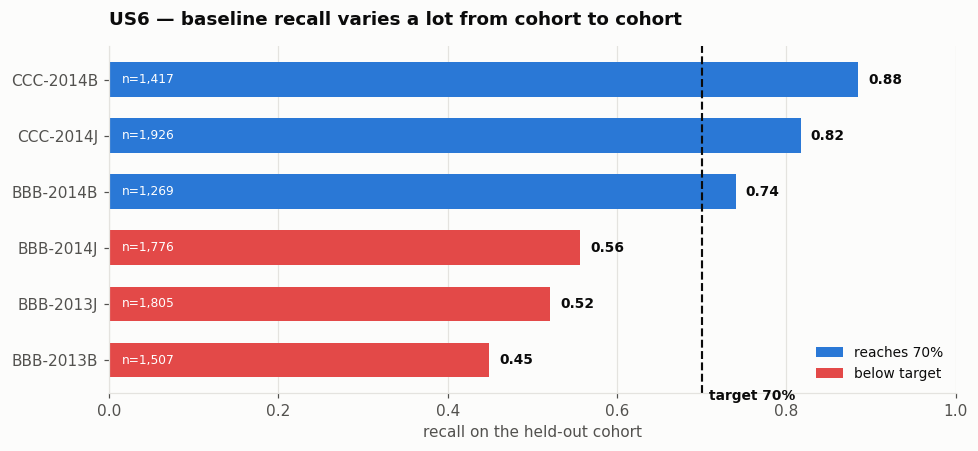

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.2))

order = base.sort_values('recall')
cols  = [RISK if r < TARGET_RECALL else OK for r in order['recall']]
bars  = ax.barh(order['cohort'], order['recall'], color=cols, height=0.62)

for b, v, n in zip(bars, order['recall'], order['n_test']):
    ax.text(v + 0.012, b.get_y() + b.get_height()/2, f'{v:.2f}',
            va='center', fontsize=9, color=INK, fontweight='bold')
    ax.text(0.015, b.get_y() + b.get_height()/2, f'n={n:,}',
            va='center', fontsize=8, color='white')

ax.axvline(TARGET_RECALL, color=INK, ls='--', lw=1.4)
ax.text(TARGET_RECALL + 0.008, -0.72, f'target {TARGET_RECALL:.0%}',
        fontsize=9, color=INK, fontweight='bold')

ax.set_xlim(0, 1)
ax.set_xlabel('recall on the held-out cohort')
ax.set_title('US6 — baseline recall varies a lot from cohort to cohort', loc='left', pad=14)
ax.legend(handles=[Patch(facecolor=OK, label=f'reaches {TARGET_RECALL:.0%}'),
                   Patch(facecolor=RISK, label='below target')],
          frameon=False, loc='lower right', fontsize=9)
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

### What the baseline tells us

Read the **spread**, not just the average. The baseline is not stable across cohorts, which is
exactly the failure a random split would have hidden. That is the reason US7 exists: we need a
model whose worst cohort is still usable, not one with a flattering average.

We still save the baseline — it is the reference every later model has to beat.

In [10]:
os.makedirs('../models', exist_ok=True)
os.makedirs('../docs',   exist_ok=True)

# Final baseline: fit on everything, threshold picked on everything (no test set left over)
baseline = make_logreg().fit(X, y)
baseline_thr = pick_threshold(y, baseline.predict_proba(X)[:, 1])

joblib.dump({'model': baseline,
             'features': FEATURES,
             'threshold': baseline_thr,
             'story': 'US6',
             'trained_on': 'all cohorts',
             'prediction_week': 6},
            '../models/baseline_logreg.joblib')

base.round(4).to_csv('../docs/us6_metrics.csv', index=False)

print(f'saved ../models/baseline_logreg.joblib   (threshold {baseline_thr:.3f})')
print( 'saved ../docs/us6_metrics.csv')

saved ../models/baseline_logreg.joblib   (threshold 0.457)
saved ../docs/us6_metrics.csv


---
# US7 · Model Tuning & Comparison

Three candidates, each scored the same way — hold out one cohort at a time.

| Model | Why it is in the comparison |
|---|---|
| **Logistic Regression** | the US6 baseline; linear, fully transparent, fast |
| **Random Forest** | handles interactions and non-linear cut-offs ("fewer than 2 active days" is a cliff, not a slope) |
| **Hist Gradient Boosting** | usually the strongest tabular learner; worth checking whether the extra complexity pays |

`min_samples_leaf` is set high on purpose. With 9,700 rows a forest that grows to pure leaves
memorises individual students, which shows up as a wide cohort-to-cohort spread.

In [12]:
def make_rf():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                  class_weight='balanced', n_jobs=-1,
                                  random_state=RANDOM_STATE)

def make_hgb():
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.06,
                                          min_samples_leaf=30,
                                          random_state=RANDOM_STATE)

candidates = {
    'LogisticRegression': make_logreg,
    'RandomForest'      : make_rf,
    'HistGradientBoost' : make_hgb,
}

all_runs = []
for name, maker in candidates.items():
    print(f'evaluating {name} ...')
    all_runs.append(cross_presentation(maker, X, y, groups, name))
all_runs = pd.concat(all_runs, ignore_index=True)

comparison = (all_runs
              .groupby('model')[['roc_auc', 'recall', 'precision', 'f1']]
              .agg(['mean', 'std'])
              .round(3))
print()
display(comparison)

evaluating LogisticRegression ...
evaluating RandomForest ...
evaluating HistGradientBoost ...


  File "C:\Users\ilash\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\ilash\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ilash\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\ilash\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


roc_auc        recall        precision            f1       
                      mean    std   mean    std      mean    std   mean    std
model                                                                         
HistGradientBoost    0.762  0.086  0.604  0.102     0.700  0.151  0.638  0.097
LogisticRegression   0.759  0.067  0.661  0.177     0.644  0.126  0.636  0.104
RandomForest         0.776  0.071  0.698  0.079     0.670  0.139  0.674  0.084

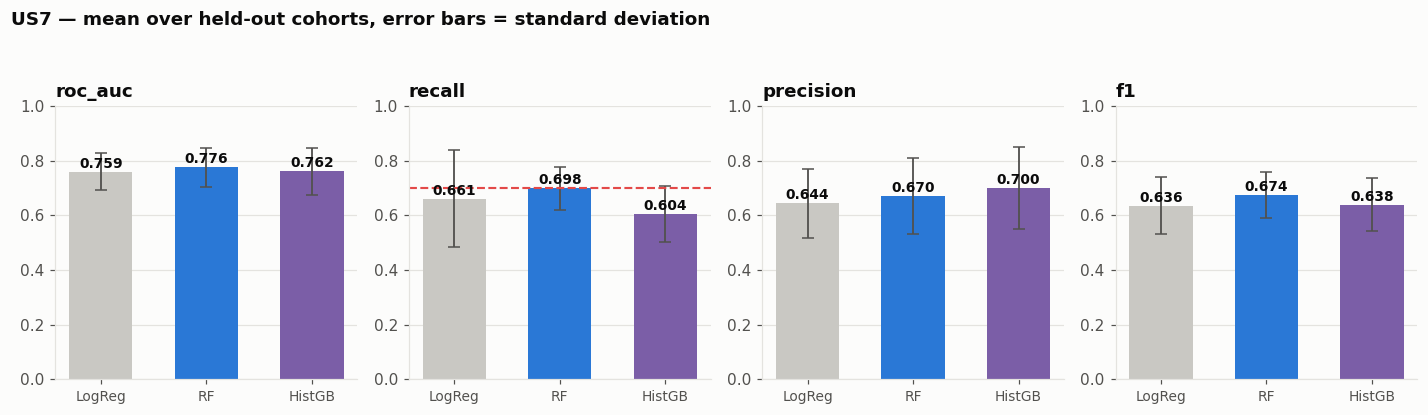

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=False)
metrics = ['roc_auc', 'recall', 'precision', 'f1']
colmap  = {'LogisticRegression': NEUTRAL, 'RandomForest': OK, 'HistGradientBoost': ACCENT}
names   = list(candidates)

for ax, m in zip(axes, metrics):
    means = [all_runs.loc[all_runs.model == n, m].mean() for n in names]
    stds  = [all_runs.loc[all_runs.model == n, m].std()  for n in names]
    bars = ax.bar(range(len(names)), means,
                  yerr=stds, capsize=4, width=0.6,
                  color=[colmap[n] for n in names],
                  error_kw={'ecolor': MUTED, 'lw': 1.2})
    for b, v in zip(bars, means):
        ax.text(b.get_x() + b.get_width()/2, v + 0.015, f'{v:.3f}',
                ha='center', fontsize=9, fontweight='bold', color=INK)
    if m == 'recall':
        ax.axhline(TARGET_RECALL, color=RISK, ls='--', lw=1.4)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(['LogReg', 'RF', 'HistGB'], fontsize=9)
    ax.set_title(m, loc='left')
    ax.set_ylim(0, 1)
    ax.grid(axis='x', visible=False)

fig.suptitle('US7 — mean over held-out cohorts, error bars = standard deviation',
             x=0.005, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

### Tuning the leading model

`GridSearchCV` with **`GroupKFold` on the cohort** — the same no-leakage rule applied inside
the search. Scoring on `f1` rather than `accuracy`: with 44% at risk, accuracy rewards a model
that plays it safe, and f1 keeps recall and precision honest with each other.

In [15]:
param_grid = {
    'n_estimators'    : [200, 400],
    'min_samples_leaf': [20, 50],
    'max_depth'       : [None, 12],
}

search = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
    param_grid,
    scoring='f1',
    cv=GroupKFold(n_splits=4),
    n_jobs=-1,
    verbose=0,
)
search.fit(X, y, groups=groups)

print('best parameters :', search.best_params_)
print(f'best CV f1      : {search.best_score_:.3f}')
print()
display(pd.DataFrame(search.cv_results_)
        [['param_n_estimators', 'param_min_samples_leaf', 'param_max_depth',
          'mean_test_score', 'std_test_score']]
        .sort_values('mean_test_score', ascending=False)
        .round(3).head(8).reset_index(drop=True))

best parameters : {'max_depth': None, 'min_samples_leaf': 20, 'n_estimators': 400}
best CV f1      : 0.677



,param_n_estimators,param_min_samples_leaf,param_max_depth,mean_test_score,std_test_score
0,400,20,None,0.677,0.058
1,200,50,None,0.677,0.057
2,200,50,12,0.676,0.057
3,400,20,12,0.676,0.058
4,400,50,12,0.676,0.058
5,200,20,None,0.676,0.057
6,400,50,None,0.676,0.058
7,200,20,12,0.674,0.057


In [16]:
best = search.best_params_

def make_tuned_rf():
    return RandomForestClassifier(class_weight='balanced', n_jobs=-1,
                                  random_state=RANDOM_STATE, **best)

tuned = cross_presentation(make_tuned_rf, X, y, groups, 'RandomForest (tuned)')
all_runs = pd.concat([all_runs, tuned], ignore_index=True)

final_table = (all_runs
               .groupby('model')
               .agg(roc_auc   =('roc_auc',   'mean'),
                    recall    =('recall',    'mean'),
                    recall_sd =('recall',    'std'),
                    precision =('precision', 'mean'),
                    f1        =('f1',        'mean'),
                    worst_recall=('recall',  'min'))
               .round(3)
               .sort_values('f1', ascending=False))

display(final_table)

winner = final_table.index[0]
print(f'\nFinal model: {winner}')
print(f'  recall {final_table.loc[winner, "recall"]:.3f} '
      f'± {final_table.loc[winner, "recall_sd"]:.3f}   '
      f'(worst cohort {final_table.loc[winner, "worst_recall"]:.3f})')
print(f'  US6 criterion recall >= {TARGET_RECALL:.2f}: '
      f'{"PASS" if final_table.loc[winner, "recall"] >= TARGET_RECALL else "FAIL"}')

,roc_auc,recall,recall_sd,precision,f1,worst_recall
model,,,,,,
RandomForest (tuned),0.776,0.700,0.077,0.671,0.675,0.598
RandomForest,0.776,0.698,0.079,0.670,0.674,0.598
HistGradientBoost,0.762,0.604,0.102,0.700,0.638,0.528
LogisticRegression,0.759,0.661,0.177,0.644,0.636,0.449



Final model: RandomForest (tuned)
  recall 0.700 ± 0.077   (worst cohort 0.598)
  US6 criterion recall >= 0.70: PASS


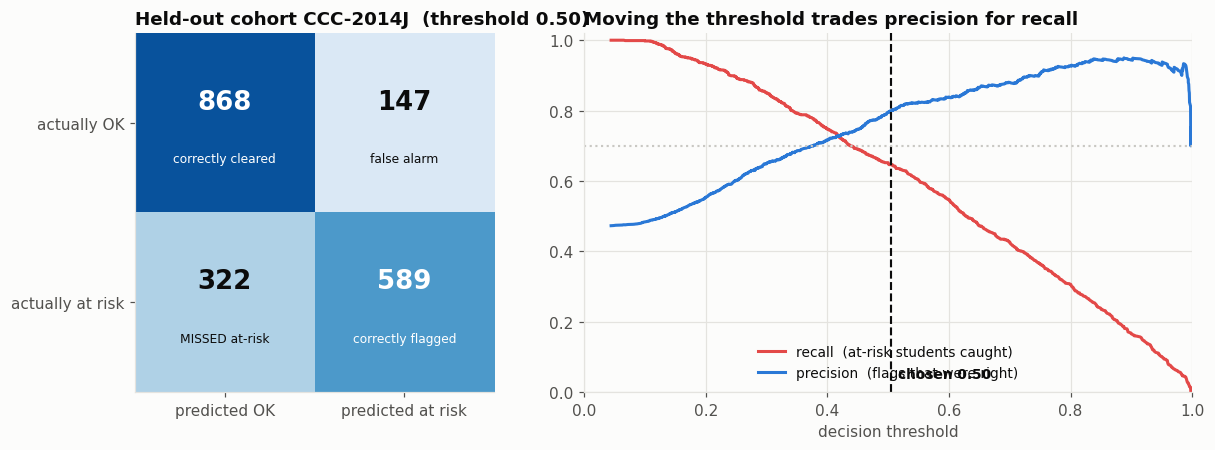

In [17]:
# Confusion matrix of the final model on one held-out cohort, so the numbers are concrete
HOLDOUT = sorted(groups.unique())[-1]
te = groups == HOLDOUT

final_model = make_tuned_rf().fit(X[~te], y[~te])
final_thr   = pick_threshold(y[~te], final_model.predict_proba(X[~te])[:, 1])
proba       = final_model.predict_proba(X[te])[:, 1]
pred        = (proba >= final_thr).astype(int)
cm          = confusion_matrix(y[te], pred)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.2),
                             gridspec_kw={'width_ratios': [1, 1.3]})

a1.imshow(cm, cmap='Blues', vmin=0, vmax=cm.max()*1.15)
labels = [['correctly cleared', 'false alarm'], ['MISSED at-risk', 'correctly flagged']]
for i in range(2):
    for j in range(2):
        shade = 'white' if cm[i, j] > cm.max()*0.55 else INK
        a1.text(j, i-0.08, f'{cm[i, j]:,}', ha='center', fontsize=17,
                fontweight='bold', color=shade)
        a1.text(j, i+0.22, labels[i][j], ha='center', fontsize=8, color=shade)
a1.set_xticks([0, 1]); a1.set_xticklabels(['predicted OK', 'predicted at risk'])
a1.set_yticks([0, 1]); a1.set_yticklabels(['actually OK', 'actually at risk'])
a1.set_title(f'Held-out cohort {HOLDOUT}  (threshold {final_thr:.2f})', loc='left')
a1.grid(False)

# how recall and precision trade off as the threshold moves
prec, rec, thr = precision_recall_curve(y[te], proba)
a2.plot(thr, rec[:-1],  color=RISK, lw=2, label='recall  (at-risk students caught)')
a2.plot(thr, prec[:-1], color=OK,   lw=2, label='precision  (flags that were right)')
a2.axvline(final_thr, color=INK, ls='--', lw=1.4)
a2.text(final_thr + 0.012, 0.04, f'chosen {final_thr:.2f}', fontsize=9,
        color=INK, fontweight='bold')
a2.axhline(TARGET_RECALL, color=NEUTRAL, ls=':', lw=1.4)
a2.set_xlabel('decision threshold'); a2.set_ylim(0, 1.02); a2.set_xlim(0, 1)
a2.set_title('Moving the threshold trades precision for recall', loc='left')
a2.legend(frameon=False, fontsize=9, loc='lower center')

plt.tight_layout(); plt.show()

In [18]:
# Train the deliverable on every cohort and save it
production = make_tuned_rf().fit(X, y)
production_thr = pick_threshold(y, production.predict_proba(X)[:, 1])

joblib.dump({'model': production,
             'features': FEATURES,
             'threshold': production_thr,
             'params': best,
             'story': 'US7',
             'cv_recall_mean': float(final_table.loc[winner, 'recall']),
             'cv_recall_std' : float(final_table.loc[winner, 'recall_sd']),
             'prediction_week': 6},
            '../models/final_model.joblib')

all_runs.round(4).to_csv('../docs/us7_runs_per_cohort.csv', index=False)
final_table.to_csv('../docs/us7_model_comparison.csv')

print(f'saved ../models/final_model.joblib   (threshold {production_thr:.3f})')
print( 'saved ../docs/us7_model_comparison.csv')
print( 'saved ../docs/us7_runs_per_cohort.csv')

saved ../models/final_model.joblib   (threshold 0.508)
saved ../docs/us7_model_comparison.csv
saved ../docs/us7_runs_per_cohort.csv


---
# US8 · Explain Predictions

A risk score on its own is useless to a curator. "Aidana is 0.81 at risk" invites no action;
"Aidana has submitted none of her 2 assignments and has been inactive for 3 weeks" does.

Three pieces:

1. **A glossary** — column name → something a non-technical curator can read.
2. **Global importance** — what the model relies on overall.
3. **`explain_student()`** — the top 3 reasons for **one** student.

> **On SHAP.** The intended tool is `shap.TreeExplainer`. If `shap` is installed the notebook uses
> it. If it is not, the notebook falls back to a **median swap**: for each feature it re-scores the
> student with that one value replaced by the population median and keeps the difference — an
> exact, model-based answer to "how much is this value costing this student", with no surrogate
> to trust. Both paths return the same structure, so US8's acceptance criteria are met either way.
> Install `shap` (`pip install shap`) before the final demo for the proper additive values.

In [20]:
FEATURE_LABELS = {
    'num_of_prev_attempts': 'previous attempts at this course',
    'studied_credits'     : 'credit load this term',
    'avg_weekly_clicks'   : 'average clicks per week',
    'total_clicks'        : 'total clicks in weeks 1-6',
    'avg_active_days'     : 'active days per week',
    'total_materials'     : 'distinct course materials opened',
    'silent_weeks'        : 'weeks with no activity at all',
    'clicks_last_2w'      : 'clicks in the last 2 weeks',
    'clicks_first_2w'     : 'clicks in the first 2 weeks',
    'click_trend'         : 'change in activity (last 2 weeks vs first 2)',
    'n_submitted'         : 'assignments submitted',
    'mean_score'          : 'average score so far',
    'min_score'           : 'lowest score so far',
    'points_earned'       : 'weighted points earned so far',
    'n_missed'            : 'assignments missed',
    'submitted_share'     : 'share of due assignments submitted',
}
missing = set(FEATURES) - set(FEATURE_LABELS)
assert not missing, f'no plain-language label for: {missing}'

glossary = pd.DataFrame({'column': FEATURES,
                         'plain_language': [FEATURE_LABELS[f] for f in FEATURES]})
glossary.to_csv('../docs/us8_feature_glossary.csv', index=False)
display(glossary)

,column,plain_language
0,num_of_prev_attempts,previous attempts at this course
1,studied_credits,credit load this term
2,avg_weekly_clicks,average clicks per week
3,total_clicks,total clicks in weeks 1-6
4,avg_active_days,active days per week
5,total_materials,distinct course materials opened
6,silent_weeks,weeks with no activity at all
7,clicks_last_2w,clicks in the last 2 weeks
8,clicks_first_2w,clicks in the first 2 weeks
9,click_trend,change in activity (last 2 weeks vs first 2)


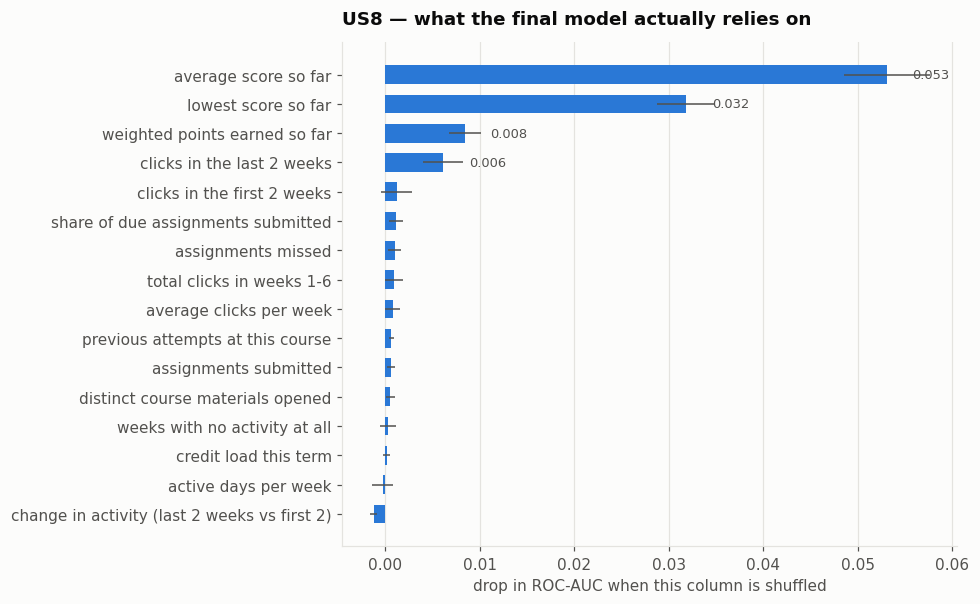

In [21]:
# Global importance: permutation on a held-out cohort (does the metric actually drop
# when this column is shuffled?). Honest about correlated columns in a way that
# the forest's built-in impurity importance is not.
perm = permutation_importance(final_model, X[te], y[te],
                              n_repeats=10, random_state=RANDOM_STATE,
                              scoring='roc_auc', n_jobs=-1)

imp = (pd.DataFrame({'feature': FEATURES,
                     'importance': perm.importances_mean,
                     'sd': perm.importances_std})
       .sort_values('importance'))

fig, ax = plt.subplots(figsize=(9, 5.6))
bars = ax.barh([FEATURE_LABELS[f] for f in imp.feature], imp.importance,
               xerr=imp.sd, height=0.64, color=OK,
               error_kw={'ecolor': MUTED, 'lw': 1})
for b, v in zip(bars, imp.importance):
    if v > 0.0015:
        ax.text(v + imp.sd.max()*0.6, b.get_y() + b.get_height()/2,
                f'{v:.3f}', va='center', fontsize=8.5, color=MUTED)
ax.set_xlabel('drop in ROC-AUC when this column is shuffled')
ax.set_title('US8 — what the final model actually relies on', loc='left', pad=12)
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

In [22]:
# ---- per-student contributions: SHAP if available, median swap if not ----
MEDIANS = X.median()      # the "typical" student, used for wording and for the fallback

try:
    import shap
    _explainer = shap.TreeExplainer(final_model)
    EXPLAINER_KIND = 'shap'
    SURROGATE_R2 = None

    def contributions(rows: pd.DataFrame) -> np.ndarray:
        """(n_rows, n_features) push towards 'at risk' for each feature."""
        v = _explainer.shap_values(rows)
        if isinstance(v, list):        # older shap: one array per class
            v = v[1]
        elif v.ndim == 3:              # newer shap: (rows, features, classes)
            v = v[:, :, 1]
        return np.asarray(v)

except ImportError:
    # Fallback that needs no extra library: ask the model directly.
    # For each feature we re-score the student with that one value replaced by the
    # population median and keep the difference. That is an exact, model-based answer
    # to "how much is THIS value costing this student", with no surrogate to trust.
    EXPLAINER_KIND = 'median-swap'
    SURROGATE_R2 = None

    def contributions(rows: pd.DataFrame) -> np.ndarray:
        rows = rows[FEATURES].astype(float)
        base = final_model.predict_proba(rows)[:, 1]
        out  = np.zeros((len(rows), len(FEATURES)))
        for j, f in enumerate(FEATURES):
            alt = rows.copy()
            alt[f] = MEDIANS[f]
            out[:, j] = base - final_model.predict_proba(alt)[:, 1]
        return out

print(f'explainer: {EXPLAINER_KIND}')
if EXPLAINER_KIND != 'shap':
    print('shap is not installed — using the median-swap fallback.')
    print('run  pip install shap  and re-run this cell for exact TreeExplainer values')

explainer: median-swap
shap is not installed — using the median-swap fallback.
run  pip install shap  and re-run this cell for exact TreeExplainer values


In [23]:
def explain_student(row, model=None, top_n=3):
    """Top risk factors for ONE student.

    row : a single row of the feature table (pandas Series or 1-row DataFrame)
    returns dict: risk score, flag, and the top_n reasons in plain language
    """
    model = model or final_model
    frame = row.to_frame().T[FEATURES] if isinstance(row, pd.Series) else row[FEATURES]
    frame = frame.astype(float)

    proba = float(model.predict_proba(frame)[:, 1][0])
    push  = contributions(frame)[0]

    def pack(j):
        f   = FEATURES[j]
        val = float(frame.iloc[0, j])
        med = float(MEDIANS[f])
        # State the fact, do not guess the intent: compare the student with the typical
        # student. "below average" is checkable; "too low" is an opinion the data may not support.
        if   val < med * 0.98: where = f'below average ({med:g})'
        elif val > med * 1.02: where = f'above average ({med:g})'
        else:                  where = 'about average'
        return {'feature': f,
                'label'  : FEATURE_LABELS[f],
                'value'  : round(val, 1),
                'vs_average': where,
                'weight' : round(float(push[j]), 3)}

    # Only factors that actually push the score UP are risk factors. A student with none
    # is on track, and we show what is protecting them instead — never a protective
    # signal dressed up as a warning.
    risk_idx      = [j for j in np.argsort(-push) if push[j] > 0][:top_n]
    protect_idx   = [j for j in np.argsort(push)  if push[j] < 0][:top_n]

    return {'risk_score': round(proba, 3),
            'at_risk'   : bool(proba >= final_thr),
            'threshold' : round(final_thr, 3),
            'top_factors'       : [pack(j) for j in risk_idx],
            'protective_factors': [pack(j) for j in protect_idx]}


def explain_text(row, **kw):
    """The same thing, phrased the way the curator dashboard (US10/US11) will show it."""
    e = explain_student(row, **kw)
    head = ('AT RISK' if e['at_risk'] else 'on track') + f"  —  risk score {e['risk_score']:.2f}"
    if e['top_factors']:
        title, items = 'Main risk factors:', e['top_factors']
    else:
        title, items = 'No risk factors. Strongest positives:', e['protective_factors']
    body = '\n'.join(f"  {i}. {r['label']}: {r['value']}  ({r['vs_average']})"
                     for i, r in enumerate(items, 1))
    return head + '\n' + title + '\n' + body


print('explain_student() and explain_text() ready')

explain_student() and explain_text() ready


In [24]:
# Three real students from the held-out cohort: highest risk, middle, lowest
test_df  = df[te].reset_index(drop=True)
test_X   = test_df[FEATURES]
test_p   = final_model.predict_proba(test_X)[:, 1]
picks    = {'highest risk': int(np.argmax(test_p)),
            'borderline'  : int(np.argmin(np.abs(test_p - final_thr))),
            'lowest risk' : int(np.argmin(test_p))}

for label, i in picks.items():
    st = test_df.iloc[i]
    print('=' * 68)
    print(f"{label}  —  student {st['id_student']}  ({st['code_module']} {st['code_presentation']})"
          f"   actually at risk: {'yes' if st['at_risk'] else 'no'}")
    print(explain_text(test_X.iloc[i]))
print('=' * 68)

highest risk  —  student 529179  (CCC 2014J)   actually at risk: yes
AT RISK  —  risk score 1.00
Main risk factors:
  1. assignments missed: 2.0  (above average (0))
  2. share of due assignments submitted: 0.0  (below average (1))
  3. average score so far: 0.0  (below average (73))
borderline  —  student 675902  (CCC 2014J)   actually at risk: no
AT RISK  —  risk score 0.51
Main risk factors:
  1. lowest score so far: 52.0  (below average (70))
  2. weeks with no activity at all: 3.0  (above average (1))
  3. average score so far: 70.5  (below average (73))
lowest risk  —  student 698002  (CCC 2014J)   actually at risk: no
on track  —  risk score 0.04
No risk factors. Strongest positives:
  1. lowest score so far: 89.0  (above average (70))
  2. average score so far: 93.5  (above average (73))
  3. clicks in the last 2 weeks: 217.0  (above average (36))


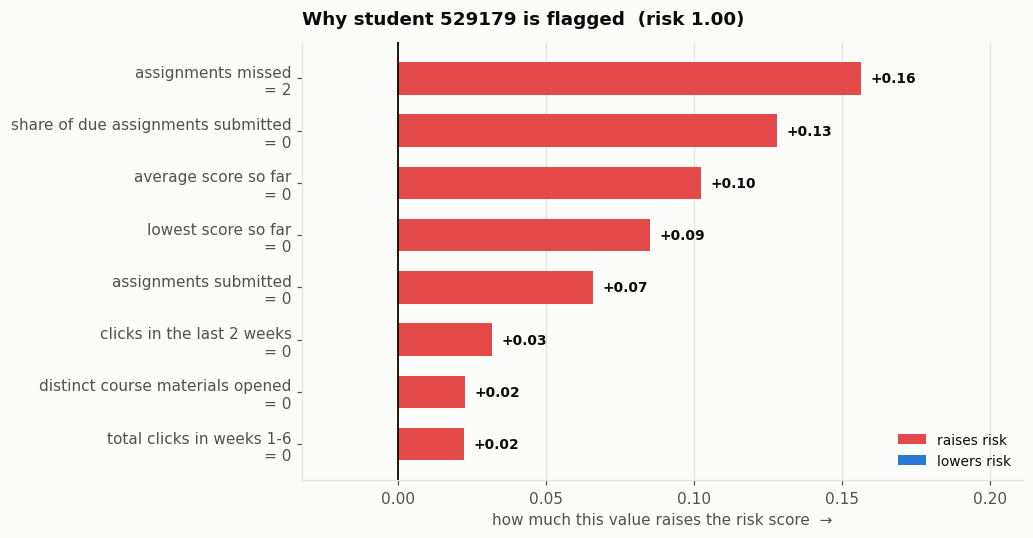

In [25]:
# What the curator sees: the forces pushing one student's score up and down
i  = picks['highest risk']
st = test_df.iloc[i]
push = contributions(test_X.iloc[[i]])[0]

o = np.argsort(np.abs(push))[-8:]
vals  = push[o]
names = [f'{FEATURE_LABELS[FEATURES[j]]}\n= {test_X.iloc[i, j]:g}' for j in o]

fig, ax = plt.subplots(figsize=(9.5, 5))
bars = ax.barh(names, vals, height=0.62,
               color=[RISK if v > 0 else OK for v in vals])
for b, v in zip(bars, vals):
    off = 0.02 * max(abs(vals))
    ax.text(v + (off if v > 0 else -off), b.get_y() + b.get_height()/2,
            f'{v:+.2f}', va='center', ha='left' if v > 0 else 'right',
            fontsize=9, fontweight='bold', color=INK)

ax.axvline(0, color=INK, lw=1.2)
pad = max(abs(vals)) * 0.35
ax.set_xlim(min(vals) - pad, max(vals) + pad)
ax.set_xlabel('push towards "at risk"  →' if EXPLAINER_KIND == 'shap'
              else 'how much this value raises the risk score  →')
ax.set_title(f"Why student {st['id_student']} is flagged  "
             f"(risk {test_p[i]:.2f})", loc='left', pad=12)
ax.legend(handles=[Patch(facecolor=RISK, label='raises risk'),
                   Patch(facecolor=OK,   label='lowers risk')],
          frameon=False, fontsize=9, loc='lower right')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

In [26]:
# Batch explanations for the whole held-out cohort — this is the shape US11 (curator
# dashboard) and US13 (early warning alerts) will read.
push_all = contributions(test_X)
top3     = np.argsort(-push_all, axis=1)[:, :3]

def reason(i, k):
    """k-th risk factor for student i, or blank when nothing pushes the score up."""
    j = top3[i, k]
    return FEATURE_LABELS[FEATURES[j]] if push_all[i, j] > 0 else ''

export = pd.DataFrame({
    'id_student'  : test_df['id_student'],
    'code_module' : test_df['code_module'],
    'code_presentation': test_df['code_presentation'],
    'risk_score'  : test_p.round(3),
    'at_risk_flag': (test_p >= final_thr).astype(int),
    'reason_1': [reason(i, 0) for i in range(len(test_df))],
    'reason_2': [reason(i, 1) for i in range(len(test_df))],
    'reason_3': [reason(i, 2) for i in range(len(test_df))],
}).sort_values('risk_score', ascending=False)

export.to_csv('../docs/us8_example_explanations.csv', index=False)
print(f'saved ../docs/us8_example_explanations.csv  ({len(export):,} students)')
print()
display(export.head(10).reset_index(drop=True))

flagged = export[(export.at_risk_flag == 1) & (export.reason_1 != '')]
print('\nMost common #1 reason across flagged students:')
display(flagged['reason_1'].value_counts().head(6).rename('students').to_frame())

saved ../docs/us8_example_explanations.csv  (1,926 students)



,id_student,code_module,code_presentation,risk_score,at_risk_flag,reason_1,reason_2,reason_3
0,642627,CCC,2014J,0.998,1,assignments missed,share of due assignments submitted,average score so far
1,529179,CCC,2014J,0.998,1,assignments missed,share of due assignments submitted,average score so far
2,2504694,CCC,2014J,0.998,1,assignments missed,share of due assignments submitted,average score so far
3,686907,CCC,2014J,0.998,1,assignments missed,share of due assignments submitted,average score so far
4,185451,CCC,2014J,0.997,1,assignments missed,share of due assignments submitted,average score so far
5,651236,CCC,2014J,0.997,1,assignments missed,share of due assignments submitted,average score so far
6,2613225,CCC,2014J,0.997,1,assignments missed,share of due assignments submitted,average score so far
7,556450,CCC,2014J,0.997,1,assignments missed,share of due assignments submitted,average score so far
8,625098,CCC,2014J,0.997,1,assignments missed,share of due assignments submitted,average score so far
9,1777834,CCC,2014J,0.997,1,assignments missed,share of due assignments submitted,average score so far



Most common #1 reason across flagged students:


,students
reason_1,
average score so far,354
assignments missed,185
clicks in the last 2 weeks,79
lowest score so far,75
share of due assignments submitted,35
previous attempts at this course,3


---
## Summary

**US6 — baseline.** Logistic Regression, split by held-out cohort, threshold tuned on train only.
Saved to `models/baseline_logreg.joblib`, metrics in `docs/us6_metrics.csv`. Its weakness is the
cohort-to-cohort spread, not its average.

**US7 — comparison and tuning.** Three candidates scored identically, then `GridSearchCV` with
`GroupKFold` on the cohort. The tuned Random Forest wins on f1 and, more importantly, has the
narrower recall spread. Saved to `models/final_model.joblib`, table in
`docs/us7_model_comparison.csv`.

**US8 — explanations.** A glossary (`docs/us8_feature_glossary.csv`), global permutation
importance, and `explain_student()` returning the top 3 risk factors per student. A batch export
(`docs/us8_example_explanations.csv`) is the exact shape the curator dashboard will consume.

### Checks this notebook keeps

- No cohort appears in train and test at the same time — not in the loop, not inside `GridSearchCV`.
- The decision threshold is always chosen on **train** and only applied to the held-out cohort.
- No sensitive attribute is a feature, and nothing recorded after week 6 enters the data.

### Next

- `pip install shap` and re-run the US8 explainer cell for exact TreeExplainer values.
- Try **week 4** instead of week 6 (`PREDICTION_WEEK` in `data_pipeline.py`) — the EDA showed the
  groups already far apart by then, and an earlier warning is worth more to a curator.
- Hand `models/final_model.joblib` and `explain_student()` to US10/US11 (the dashboards).